# Adding Problem: Long-Term Dependency Learning Task

This notebook implements the adding problem, a benchmark task for evaluating the ability of RNNs to learn long-term dependencies. The task requires computing the sum of two specific numbers from a sequence of random numbers.

## Task Description

- Input: 2-dimensional vector at each time step
  - First dimension: Random number in [0, 1]
  - Second dimension: Boolean indicator (1 for numbers to add, 0 otherwise)
- Sequence length: 20 time steps
- Objective: Sum the two numbers where the boolean indicator is 1
- This tests the network's ability to remember and combine information from different time steps

We will compare the performance of two network architectures:

1. **Net**: RNN with excitatory/inhibitory separation
2. **SimpleNet**: Standard vanilla RNN


## 1. Setup and Imports


In [21]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader
import warnings
warnings.filterwarnings('ignore')

from pdm_model import Net, SimpleNet

# Set device
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

Using device: cuda


## 2. Adding Problem Dataset


In [22]:
class SortDataset(Dataset):
    def __init__(self, seq_len=64, num_samples=100000):
        self.seq_len = seq_len
        self.num_samples = num_samples
        number = torch.rand(num_samples, seq_len)
        argsort = torch.argsort(number, dim=1)
        # argsort_till_t = torch.zeros(num_samples, seq_len, seq_len)
        # for i in range(seq_len):
        #     argsort_till_t[:, i, :i+1] = torch.argsort(number[:, :i+1], dim=1, descending=False)
        #     argsort_till_t[:, i, i+1:] = -11  # padding with -1
        # self.argsort_till_t = argsort_till_t.to(torch.long)
        self.data = number.unsqueeze(-1)
        self.target = argsort

    def __len__(self):
        return self.num_samples

    def __getitem__(self, idx):
        return self.data[idx], self.target[idx]

# Create datasets
train_dataset = SortDataset(seq_len=5, num_samples=50000)
test_dataset = SortDataset(seq_len=5, num_samples=1000)

print(f"Training dataset size: {len(train_dataset)}")
print(f"Test dataset size: {len(test_dataset)}")

# Show example
sample_input, sample_target = train_dataset[0]
print(f"\nExample input shape: {sample_input}")
print(f"Example target: {sample_target}")

Training dataset size: 50000
Test dataset size: 1000

Example input shape: tensor([[0.4206],
        [0.3326],
        [0.3261],
        [0.3804],
        [0.9555]])
Example target: tensor([2, 1, 3, 0, 4])


## 3. Visualize Sample Data


In [23]:
def visualize_adding_problem_sample(dataset, idx=0):
    """
    Visualize a sample from the adding problem dataset.
    """
    input_seq, target = dataset[idx]
    input_seq = input_seq[0]
    seq_len = input_seq.shape[0]

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

    # Plot the random numbers
    ax1.plot(range(seq_len), input_seq, 'b-', linewidth=2, label='Random numbers')
    # Highlight the numbers to be added
    marked_indices = np.where(input_seq == -1)[0]
    ax1.scatter(marked_indices, input_seq[marked_indices],
               color='red', s=100, zorder=5, label='Numbers to add')
    ax1.set_ylabel('Value')
    ax1.set_title(f'Adding Problem Sample (Target: {target})')
    ax1.legend()
    ax1.grid(True, alpha=0.3)

    # Plot the indicators
    ax2.plot(range(seq_len), target, 'g-', linewidth=3, label='Target')
    ax2.set_xlabel('Time Step')
    ax2.set_ylabel('Target')
    ax2.set_ylim(-0.1, 1.1)
    ax2.legend()
    ax2.grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()


    print(f"Target: {target}")

# Visualize a few samples
# visualize_adding_problem_sample(train_dataset, 0)
# visualize_adding_problem_sample(train_dataset, 1)

In [24]:
def loss_fn(outputs, targets, criterion):
    """
    Compute cross-entropy loss between model outputs and targets.
    """
    T, B, D = outputs.shape
    predictions = outputs.reshape(T, B, T, T)
    assert targets.shape == (B, T, T)
    loss = 0
    acc = 0
    for t in range(T):
        prediction_t = predictions[t, :, :t+1].reshape(B*(t+1), T)
        target_t = targets[:, t, :t+1].reshape(B*(t+1))
        assert torch.all(target_t != -1)
        loss += criterion(prediction_t, target_t)
    loss /= T
    acc = predictions[-1].argmax(dim=-1).eq(targets[:,-1]).float().mean().item()
    return loss, acc

## 4. Training Functions


In [25]:
def train_model(model, train_loader, test_loader, epochs=100, lr=0.001):
    """
    Train a model on the adding problem.
    """
    if isinstance(model, Net):
        special_params, other_params = [], []
        for name, p in model.named_parameters():
            if name == "lstm.eimask_logit":   # 或者用 name.endswith("eimask_logit")
                special_params.append(p)
                # assert p.requires_grad, "eimask_logit should be trainable"
            else:
                other_params.append(p)
        optimizer = torch.optim.Adam([{'params': special_params, 'lr': lr*100},
                                      {'params': other_params, 'lr': lr}])
    else:
        # For SimpleNet, use a single learning rate
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    criterion = nn.CrossEntropyLoss()
    # criterion = nn.L1Loss()

    train_losses = torch.zeros(epochs)
    test_every = 100
    test_losses = torch.zeros(epochs // test_every)
    test_accs = torch.zeros(epochs // test_every)

    model.train()

    for epoch in range(epochs):
        # print(epoch)
        # Training
        total_train_loss = 0
        num_batches = 0

        # for batch_inputs, batch_targets in train_loader:
        batch_inputs, batch_targets = next(iter(train_loader))
        batch_inputs = batch_inputs.to(device).transpose(0, 1)  # (seq_len, batch_size, input_size)
        # print('batch_inputs:', batch_inputs.shape)
        batch_targets = batch_targets.to(device)  # (batch_size, seq_len)
        B, T = batch_targets.shape

        # print('batch_targets:', batch_targets.shape)

        optimizer.zero_grad()

        # Forward pass
        outputs, eimask_logit, hidden = model(batch_inputs)

        predictions = outputs[-1].reshape(B, T, T).flatten(0,1)
        target = batch_targets.flatten(0,1)
        decoding_loss = criterion(predictions, target)
        # decoding_loss, acc = loss_fn(outputs, batch_targets, criterion)

        if model.entropy_loss:
            eimask_prob = F.softmax(eimask_logit, dim=-1)
            eimask_entropy = -torch.sum(eimask_prob * torch.log(eimask_prob + 1e-10), dim=-1)
            entropy_loss = torch.mean(eimask_entropy)  # Add entropy regularization
        else:
            entropy_loss = 0.0

        loss = 1 * entropy_loss + decoding_loss
        # Backward pass
        loss.backward()
        # Gradient clipping for stability
        # torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        optimizer.step()

        total_train_loss += loss.item()
        num_batches += 1

        avg_train_loss = total_train_loss / num_batches
        train_losses[epoch] = avg_train_loss

        # Testing
        if epoch % test_every == 0:
            model.eval()
            total_test_loss = 0
            total_test_accuracy = 0
            num_test_batches = 0

            with torch.no_grad():
                for batch_inputs, batch_targets in test_loader:
                    batch_inputs = batch_inputs.to(device).transpose(0, 1)
                    batch_targets = batch_targets.to(device)  # (batch_size, seq_len)
                    B, T = batch_targets.shape

                    outputs, _, hidden = model(batch_inputs)
                    # print('outputs:', outputs.shape)
                    predictions = outputs[-1].reshape(B, T, T).flatten(0,1)
                    target = batch_targets.flatten(0,1)

                    loss = criterion(predictions, target)
                    # loss, accuracy = loss_fn(outputs, batch_targets, criterion)
                    predict_label = torch.argmax(predictions, dim=-1)
                    accuracy = (predict_label == target).float().mean().item()
                    total_test_loss += loss.item()
                    total_test_accuracy += accuracy
                    num_test_batches += 1

            avg_test_loss = total_test_loss / num_test_batches
            avg_test_accuracy = total_test_accuracy / num_test_batches
            test_losses[epoch // test_every] = avg_test_loss
            test_accs[epoch // test_every] = avg_test_accuracy

            print(f'Epoch [{epoch:4d}/{epochs}], Train Loss: {avg_train_loss:.6f}, Test Loss: {avg_test_loss:.6f}, Test Acc: {avg_test_accuracy:.4f}')

            model.train()

    return train_losses, test_losses

def evaluate_model(model, test_loader):
    """
    Evaluate model performance on test set.
    """
    model.eval()
    total_loss = 0
    total_accuracy = 0
    predictions = []
    targets = []

    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for batch_inputs, batch_targets in test_loader:
            batch_inputs = batch_inputs.to(device).transpose(0, 1)
            batch_targets = batch_targets.to(device)
            B, T = batch_targets.shape

            outputs, _, hidden = model(batch_inputs)
            preds = outputs[-1].reshape(B, T, T).flatten(0,1)
            target = batch_targets.flatten(0,1)

            loss = criterion(preds, target)
            # loss, acc = loss_fn(outputs, batch_targets, criterion)
            total_loss += loss.item()
            # total_accuracy += acc

            predictions.extend(preds.cpu().numpy())
            targets.extend(batch_targets.cpu().numpy())

    avg_loss = total_loss / len(test_loader)
    accuracy = total_accuracy / len(test_loader)
    # print('type:', type(predictions), type(targets))
    # print(predictions, np.stack(predictions).shape)
    # print(targets, np.concatenate(targets).shape)
    # print('predictions shape:', np.stack(predictions).shape, 'targets shape:', np.concatenate(targets).shape)
    accuracy = np.mean((np.argmax(np.stack(predictions), axis=-1) == np.concatenate(targets)).astype(np.float32))

    return avg_loss, accuracy, predictions, targets

## 5. Experiment: Compare Net vs SimpleNet


In [ ]:
# Experiment parameters
n_seeds = 5
epochs = 5000
batch_size = 64
hidden_size = 64
input_size = 1  # [number, indicator]
output_size = 25  # regression output

# Create data loaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Storage for results
results = {
    'net': {'train_losses': [], 'test_losses': [], 'final_acc': []},
    'simple': {'train_losses': [], 'test_losses': [], 'final_acc': []}
}

print(f"Running experiment with {n_seeds} seeds...\n")
lr_ei = 1e-2
lr_simple = 1e-3
for seed in range(n_seeds):
    print(f"=== Seed {seed + 1}/{n_seeds} ===")

    # Set random seeds for reproducibility
    torch.manual_seed(seed)
    np.random.seed(seed)

    # Train Net (EI-separated RNN)
    print("Training Net (EI-separated RNN)...")
    net = Net(ob_size=input_size, num_h=hidden_size, act_size=output_size, entropy_loss=True).to(device)
    train_losses_net, test_losses_net = train_model(net, train_loader, test_loader, epochs=epochs, lr=lr_ei)

    # Evaluate Net
    _, acc_net, net_predictions, net_targets = evaluate_model(net, test_loader)

    results['net']['train_losses'].append(train_losses_net)
    results['net']['test_losses'].append(test_losses_net)
    results['net']['final_acc'].append(acc_net)
    print(f"Net - Final Acc: {acc_net:.6f}")


    # Train SimpleNet (vanilla RNN)
    print("Training SimpleNet (vanilla RNN)...")
    simple_net = SimpleNet(ob_size=input_size, num_h=hidden_size, act_size=output_size).to(device)
    train_losses_simple, test_losses_simple = train_model(simple_net, train_loader, test_loader, epochs=epochs,lr=lr_simple)

    # Evaluate SimpleNet
    _, acc_simple, simple_predictions, simple_targets = evaluate_model(simple_net, test_loader)

    results['simple']['train_losses'].append(train_losses_simple.detach().cpu().numpy())
    results['simple']['test_losses'].append(test_losses_simple.detach().cpu().numpy())
    results['simple']['final_acc'].append(acc_simple)
    print(f"SimpleNet - Final Acc: {acc_simple:.6f}")




    print()

print("Experiment completed!")

Running experiment with 5 seeds...

=== Seed 1/5 ===
Training Net (EI-separated RNN)...
Epoch [   0/5000], Train Loss: 2.453547, Test Loss: 1.703356, Test Acc: 0.2007
Epoch [ 100/5000], Train Loss: 1.495182, Test Loss: 1.489488, Test Acc: 0.3161
Epoch [ 200/5000], Train Loss: 0.851396, Test Loss: 0.882710, Test Acc: 0.5800
Epoch [ 300/5000], Train Loss: 0.728865, Test Loss: 0.731765, Test Acc: 0.6655
Epoch [ 400/5000], Train Loss: 0.606577, Test Loss: 0.630238, Test Acc: 0.7242
Epoch [ 500/5000], Train Loss: 0.582702, Test Loss: 0.574880, Test Acc: 0.7511
Epoch [ 600/5000], Train Loss: 0.535406, Test Loss: 0.529456, Test Acc: 0.7789
Epoch [ 700/5000], Train Loss: 0.500434, Test Loss: 0.482739, Test Acc: 0.7910
Epoch [ 800/5000], Train Loss: 0.458517, Test Loss: 0.460495, Test Acc: 0.8004
Epoch [ 900/5000], Train Loss: 0.445617, Test Loss: 0.457150, Test Acc: 0.8001
Epoch [1000/5000], Train Loss: 0.421402, Test Loss: 0.465087, Test Acc: 0.7966
Epoch [1100/5000], Train Loss: 0.505252, Te

## 6. Results Analysis


In [27]:
# Print summary statistics
print("=== Final Results Summary ===")
print(f"Number of seeds: {n_seeds}")
print(f"Training epochs: {epochs}")
print(f"Hidden size: {hidden_size}")
print(f"Sequence length: 20")
print()

# Net results
net_acc_mean = np.mean(results['net']['final_acc'])
net_acc_std = np.std(results['net']['final_acc'])

print(f"Net (EI-separated RNN):")
print(f"  Acc: {net_acc_mean:.6f} ± {net_acc_std:.6f}")

# SimpleNet results
simple_acc_mean = np.mean(results['simple']['final_acc'])
simple_acc_std = np.std(results['simple']['final_acc'])

print(f"\nSimpleNet (vanilla RNN):")
print(f"  MSE: {simple_acc_mean:.6f} ± {simple_acc_std:.6f}")

# Improvement calculation
acc_improvement = (net_acc_mean - simple_acc_mean) / simple_acc_mean * 100

print(f"\n=== Performance Comparison ===")
print(f"Acc improvement (Net vs SimpleNet): {acc_improvement:.2f}%")

if acc_improvement > 0:
    print("Net (EI-separated) performs better than SimpleNet (vanilla RNN)")
else:
    print("SimpleNet (vanilla RNN) performs better than Net (EI-separated)")

=== Final Results Summary ===
Number of seeds: 5
Training epochs: 5000
Hidden size: 64
Sequence length: 20

Net (EI-separated RNN):
  Acc: 0.900960 ± 0.006489

SimpleNet (vanilla RNN):
  MSE: 0.862520 ± 0.007677

=== Performance Comparison ===
Acc improvement (Net vs SimpleNet): 4.46%
Net (EI-separated) performs better than SimpleNet (vanilla RNN)


## 7. Visualization


net train mean: [2.5347953  2.0215688  1.7953999  ... 0.22930999 0.25066736 0.23150165]
(array([], dtype=int64), array([], dtype=int64))


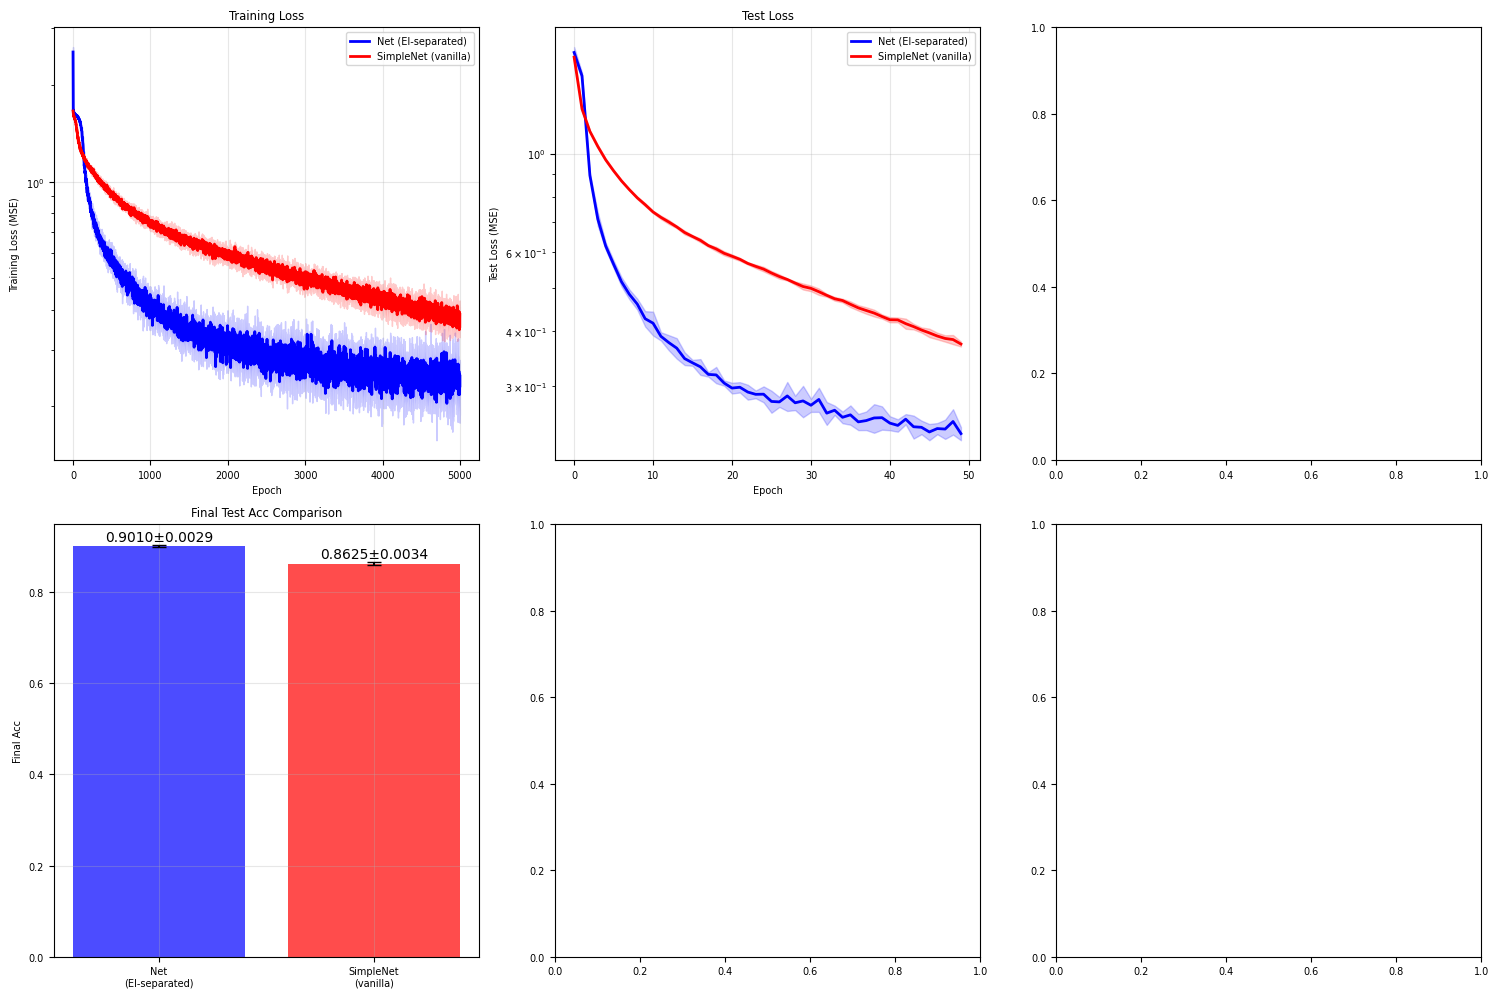

In [28]:
def plot_learning_curves(results, n_seeds):
    """
    Plot learning curves for both models.
    """
    fig, ((ax1, ax2, ax3), (ax4, ax5, ax6)) = plt.subplots(2, 3, figsize=(15, 10))

    # Training loss curves
    net_train_losses = np.array(results['net']['train_losses'])
    simple_train_losses = np.array(results['simple']['train_losses'])

    net_train_mean = np.mean(net_train_losses, axis=0)
    net_train_std = np.std(net_train_losses, axis=0)
    simple_train_mean = np.mean(simple_train_losses, axis=0)
    simple_train_std = np.std(simple_train_losses, axis=0)
    print('net train mean:', net_train_mean)
    print(np.where(net_train_losses>100))

    epochs_range = range(len(net_train_mean))

    ax1.plot(epochs_range, net_train_mean, 'b-', label='Net (EI-separated)', linewidth=2)
    ax1.fill_between(epochs_range, net_train_mean - net_train_std, net_train_mean + net_train_std, alpha=0.2, color='blue')
    ax1.plot(epochs_range, simple_train_mean, 'r-', label='SimpleNet (vanilla)', linewidth=2)
    ax1.fill_between(epochs_range, simple_train_mean - simple_train_std, simple_train_mean + simple_train_std, alpha=0.2, color='red')
    ax1.set_xlabel('Epoch')
    ax1.set_ylabel('Training Loss (MSE)')
    ax1.set_title('Training Loss')
    ax1.legend()
    ax1.grid(True, alpha=0.3)
    ax1.set_yscale('log')

    # Test loss curves (subset of epochs)
    if results['net']['test_losses'][0] is not None:  # Check if test losses exist
        net_test_losses = np.array(results['net']['test_losses'])
        simple_test_losses = np.array(results['simple']['test_losses'])

        net_test_mean = np.mean(net_test_losses, axis=0)
        net_test_std = np.std(net_test_losses, axis=0)
        simple_test_mean = np.mean(simple_test_losses, axis=0)
        simple_test_std = np.std(simple_test_losses, axis=0)

        test_epochs = range(0, len(net_train_mean))[:len(net_test_mean)]

        ax2.plot(test_epochs, net_test_mean, 'b-', label='Net (EI-separated)', linewidth=2)
        ax2.fill_between(test_epochs, net_test_mean - net_test_std, net_test_mean + net_test_std, alpha=0.2, color='blue')
        ax2.plot(test_epochs, simple_test_mean, 'r-', label='SimpleNet (vanilla)', linewidth=2)
        ax2.fill_between(test_epochs, simple_test_mean - simple_test_std, simple_test_mean + simple_test_std, alpha=0.2, color='red')
        ax2.set_xlabel('Epoch')
        ax2.set_ylabel('Test Loss (MSE)')
        ax2.set_title('Test Loss')
        ax2.legend()
        ax2.grid(True, alpha=0.3)
        ax2.set_yscale('log')

    # Final MSE comparison
    net_acc = results['net']['final_acc']
    simple_acc = results['simple']['final_acc']

    x_pos = [0, 1]
    acc_means = [np.mean(net_acc), np.mean(simple_acc)]
    acc_stds = [np.std(net_acc)/np.sqrt(len(net_acc)), np.std(simple_acc)/np.sqrt(len(simple_acc))]

    bars = ax4.bar(x_pos, acc_means, yerr=acc_stds, capsize=5,
                   color=['blue', 'red'], alpha=0.7,
                   label=['Net (EI-separated)', 'SimpleNet (vanilla)'])
    ax4.set_ylabel('Final Acc')
    ax4.set_title('Final Test Acc Comparison')
    ax4.set_xticks(x_pos)
    ax4.set_xticklabels(['Net\n(EI-separated)', 'SimpleNet\n(vanilla)'])
    ax4.grid(True, alpha=0.3)

    # Add value labels on bars
    for i, (bar, mean, std) in enumerate(zip(bars, acc_means, acc_stds)):
        ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + std + 0.001,
                f'{mean:.4f}±{std:.4f}', ha='center', va='bottom', fontsize=10)


    plt.tight_layout()
    plt.show()

# Plot the results
plot_learning_curves(results, n_seeds)

In [29]:
print(1)

1


## 8. Test Predictions Visualization


In [30]:
# # Train final models for prediction visualization
# torch.manual_seed(0)
# np.random.seed(0)

# # Train final models
# final_net = Net(ob_size=input_size, num_h=hidden_size, act_size=output_size, entropy_loss=True).to(device)
# final_simple = SimpleNet(ob_size=input_size, num_h=hidden_size, act_size=output_size).to(device)

# print("Training final models for prediction visualization...")
# train_model(final_net, train_loader, test_loader, epochs=epochs)
# train_model(final_simple, train_loader, test_loader, epochs=epochs)

# # Get predictions
# _, _, _, net_predictions, net_targets = evaluate_model(final_net, test_loader)
# _, _, _, simple_predictions, simple_targets = evaluate_model(final_simple, test_loader)

# # Plot predictions vs targets
# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# # Net predictions
# ax1.scatter(net_targets, net_predictions, alpha=0.6, color='blue')
# ax1.plot([0, 2], [0, 2], 'r--', linewidth=2, label='Perfect prediction')
# ax1.set_xlabel('True Values')
# ax1.set_ylabel('Predicted Values')
# ax1.set_title('Net (EI-separated RNN) Predictions')
# ax1.legend()
# ax1.grid(True, alpha=0.3)
# ax1.set_aspect('equal')

# # Calculate correlation
# net_corr = np.corrcoef(net_targets, net_predictions)[0, 1]
# ax1.text(0.05, 0.95, f'Correlation: {net_corr:.4f}',
#          transform=ax1.transAxes, verticalalignment='top',
#          bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# # SimpleNet predictions
# ax2.scatter(simple_targets, simple_predictions, alpha=0.6, color='red')
# ax2.plot([0, 2], [0, 2], 'r--', linewidth=2, label='Perfect prediction')
# ax2.set_xlabel('True Values')
# ax2.set_ylabel('Predicted Values')
# ax2.set_title('SimpleNet (vanilla RNN) Predictions')
# ax2.legend()
# ax2.grid(True, alpha=0.3)
# ax2.set_aspect('equal')

# # Calculate correlation
# simple_corr = np.corrcoef(simple_targets, simple_predictions)[0, 1]
# ax2.text(0.05, 0.95, f'Correlation: {simple_corr:.4f}',
#          transform=ax2.transAxes, verticalalignment='top',
#          bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# plt.tight_layout()
# plt.show()

# print(f"Net correlation: {net_corr:.4f}")
# print(f"SimpleNet correlation: {simple_corr:.4f}")